# Análise Exploratória e Estatística de Experimentos End-to-End (RAG vs. LLM-only)

## 1. Introdução e Configuração

### Objetivo do Experimento
Este notebook realiza uma análise exploratória, quantitativa e estatística de experimentos End-to-End que avaliam arquiteturas de **Retrieval-Augmented Generation (RAG)** em comparação com uma abordagem **LLM-only** (baseline sem recuperação de contexto).

### Arquiteturas e Desenho Experimental
O experimento avalia 5 configurações distintas:
- **Baseline (`llm_only`)**: Resposta gerada diretamente pelo LLM sem acesso a documentos/contexto.
- **Configurações RAG (Desenho Fatorial $2 \times 2$)**:
  1. `tokens-256-topk-1`: Chunk size = 256 tokens, Top-k = 1 chunk.
  2. `tokens-256-topk-3`: Chunk size = 256 tokens, Top-k = 3 chunks.
  3. `tokens-512-topk-1`: Chunk size = 512 tokens, Top-k = 1 chunk.
  4. `tokens-512-topk-3`: Chunk size = 512 tokens, Top-k = 3 chunks.

### Fatores Avaliados
- **Fator 1 (Chunk Size)**: 256 vs. 512 tokens.
- **Fator 2 (Top-k)**: 1 vs. 3 chunks recuperados.

---

### Dependências e Instalação
Para executar este notebook em um ambiente Python local ou Jupyter, certifique-se de que as seguintes dependências estão instaladas:
```bash
pip install pandas numpy matplotlib scipy seaborn ipython
```

In [54]:
# Importação das bibliotecas necessárias
import os
import json
import warnings
from pathlib import Path
from typing import Dict, List, Any, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from IPython.display import display, Markdown

# Tentar importar seaborn para refinamentos visuais opcionais
try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False

warnings.filterwarnings('ignore')

# Configuração global de semente aleatória para reproduzibilidade
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Configurações de exibição do Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# Configuração de estilo de gráficos com Matplotlib
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.autolayout'] = True

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


### Definição do Diretório do Experimento
**Atenção**: Para analisar outro experimento consolidado, altere apenas a variável `EXPERIMENT_DIR` abaixo.

In [55]:
# Seleção do diretório do experimento
EXPERIMENT_DIR = Path("app/evaluation/evaluation_results/end_to_end/consolidated_120_cases_20261108T165307Z")

# Identificadores padrão das abordagens avaliadas
APPROACHES = [
    "tokens-256-topk-1",
    "tokens-256-topk-3",
    "tokens-512-topk-1",
    "tokens-512-topk-3",
    "llm_only"
]
RAG_APPROACHES = [app for app in APPROACHES if app != "llm_only"]

print(f"Caminho do experimento configurado para: {EXPERIMENT_DIR.resolve()}")

Caminho do experimento configurado para: /home/isaac/mestrado/disciplinas/ia025a/app/evaluation/evaluation_results/end_to_end/consolidated_120_cases_20261108T165307Z


## 2. Carregamento e Inspeção dos Arquivos

Nesta seção, implementamos funções auxiliares robustas para ler arquivos JSON e JSONL sem modificar os arquivos de origem, tratando exceções e arquivos opcionais (ex: ausência de recuperação no `llm_only`).

In [56]:
def load_json(filepath: Path) -> Optional[Dict[str, Any]]:
    """Lê um arquivo JSON com tratamento de erros."""
    if not filepath.exists():
        return None
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            return json.load(f)
    except Exception as e:
        print(f"[AVISO] Erro ao ler JSON {filepath}: {e}")
        return None

def load_jsonl(filepath: Path) -> List[Dict[str, Any]]:
    """Lê um arquivo JSONL linha por linha com tratamento de erros."""
    if not filepath.exists():
        return []
    records = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line_num, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                print(f"[AVISO] Erro ao decodificar JSONL {filepath} linha {line_num}: {e}")
    return records

# Carregamento dos metadados globais
global_manifest = load_json(EXPERIMENT_DIR / "manifest.json")
global_comparison = load_json(EXPERIMENT_DIR / "comparison.json")

# Dicionários para armazenar dados brutos e DataFrames por abordagem
raw_data = {app: {} for app in APPROACHES}
dfs_predictions = {}
dfs_scores = {}
dfs_retrieval = {}
dfs_pairs = {}
dfs_eval_manifest = {}
dfs_eval_summary = {}

for app in APPROACHES:
    app_dir = EXPERIMENT_DIR / app
    eval_dir = app_dir / "evaluation"
    
    # Leitura JSONL
    preds = load_jsonl(app_dir / "predictions.jsonl")
    retrs = load_jsonl(app_dir / "retrieval.jsonl") if (app_dir / "retrieval.jsonl").exists() else []
    pairs = load_jsonl(app_dir / "pairs.jsonl") if (app_dir / "pairs.jsonl").exists() else []
    scores = load_jsonl(eval_dir / "scores.jsonl") if (eval_dir / "scores.jsonl").exists() else []
    
    # Leitura JSON de metadados específicos da abordagem
    eval_manifest = load_json(eval_dir / "manifest.json")
    eval_summary = load_json(eval_dir / "summary.json")
    
    # Armazenamento bruto
    raw_data[app] = {
        "predictions": preds,
        "retrieval": retrs,
        "pairs": pairs,
        "scores": scores,
        "eval_manifest": eval_manifest,
        "eval_summary": eval_summary
    }
    
    # Conversão para DataFrames
    if preds: dfs_predictions[app] = pd.DataFrame(preds)
    if retrs: dfs_retrieval[app] = pd.DataFrame(retrs)
    if pairs: dfs_pairs[app] = pd.DataFrame(pairs)
    if scores: dfs_scores[app] = pd.DataFrame(scores)

print("Carregamento concluído com sucesso.")

Carregamento concluído com sucesso.


In [57]:
# Resumo do carregamento dos arquivos por abordagem
file_counts = []
for app in APPROACHES:
    file_counts.append({
        "Abordagem": app,
        "predictions.jsonl": len(raw_data[app]["predictions"]),
        "scores.jsonl": len(raw_data[app]["scores"]),
        "retrieval.jsonl": len(raw_data[app]["retrieval"]),
        "pairs.jsonl": len(raw_data[app]["pairs"]),
        "Possui Summary": raw_data[app]["eval_summary"] is not None,
        "Possui Manifest": raw_data[app]["eval_manifest"] is not None
    })

df_file_counts = pd.DataFrame(file_counts)
display(Markdown("### Resumo de Contagem de Registros por Abordagem"))
display(df_file_counts)

if global_manifest:
    display(Markdown("### Metadados do Experimento (`manifest.json`)"))
    display(pd.DataFrame([global_manifest]))

### Resumo de Contagem de Registros por Abordagem

,Abordagem,predictions.jsonl,scores.jsonl,retrieval.jsonl,pairs.jsonl,Possui Summary,Possui Manifest
0,tokens-256-topk-1,120,120,120,40,True,True
1,tokens-256-topk-3,120,120,120,40,True,True
2,tokens-512-topk-1,120,120,120,40,True,True
3,tokens-512-topk-3,120,120,120,40,True,True
4,llm_only,120,120,0,0,True,True


### Metadados do Experimento (`manifest.json`)

,run_id,timestamp_utc,stage,protocol,execution_mode,fixed_top_k,fixed_chunk_size,chunk_overlap_tokens,build_indexes,dependencies,corpus,cases_count,cases_sha256,output_dir,comparisons_count,retrieval_count,errors,state,runs,generation_model,ragas_version,enabled_metrics,comparison_path,llm_only_predictions_path,persistence,source_runs,consolidation
0,consolidated_120_cases_20261108T165307Z,2026-11-08T16:53:08.134571+00:00,consolidated_end_to_end_rag_vs_llm_only,full_factorial,consolidated_all_combinations,None,None,50,True,"{'python': '3.11.18', 'chromadb': '1.5.9', 'py...","{'prepared_dir': '/data/retrieval/prepared', '...",120,f5a282ea6bbf34c832ef6e8890000d67bb778df898eb2b...,/home/isaac/mestrado/disciplinas/ia025a/app/ev...,4,480,0,complete,"[{'setting': 'tokens-256-topk-1', 'chunk_size'...",qwen2.5:1.5b,0.4.3,"[answer_relevancy, bleu, rouge1, rouge2, rouge...",/home/isaac/mestrado/disciplinas/ia025a/app/ev...,/home/isaac/mestrado/disciplinas/ia025a/app/ev...,append_and_fsync_after_each_completed_pair,"[{'run_id': '20261106T013753_d8f5d9e4', 'direc...",{'method': 'concatenate_individual_records_and...


## 3. Verificação da Integridade dos Dados

Nesta seção, inspecionamos os identificadores (`case_id`), verificamos se há duplicatas ou ausências e analisamos o status de execução de recuperação, geração e avaliação.

In [58]:
integrity_report = []
all_case_ids_per_app = {}

for app in APPROACHES:
    df_p = dfs_predictions.get(app, pd.DataFrame())
    df_s = dfs_scores.get(app, pd.DataFrame())
    
    p_ids = df_p['case_id'].tolist() if 'case_id' in df_p.columns else []
    s_ids = df_s['case_id'].tolist() if 'case_id' in df_s.columns else []
    
    unique_p_ids = set(p_ids)
    all_case_ids_per_app[app] = unique_p_ids
    
    integrity_report.append({
        "Abordagem": app,
        "Total Predictions": len(p_ids),
        "Unique Pred IDs": len(unique_p_ids),
        "Dup Pred IDs": len(p_ids) - len(unique_p_ids),
        "Total Scores": len(s_ids),
        "Unique Score IDs": len(set(s_ids)),
        "Preds sem Scores": len(unique_p_ids - set(s_ids))
    })

df_integrity = pd.DataFrame(integrity_report)
display(Markdown("### Relatório de Integridade de IDs por Abordagem"))
display(df_integrity)

# Interseção e união de case_ids entre todas as abordagens
common_ids = set.intersection(*all_case_ids_per_app.values()) if all_case_ids_per_app else set()
union_ids = set.union(*all_case_ids_per_app.values()) if all_case_ids_per_app else set()

print(f"Total de case_ids únicos (União): {len(union_ids)}")
print(f"Total de case_ids comuns a TODAS as 5 abordagens (Interseção): {len(common_ids)}")

### Relatório de Integridade de IDs por Abordagem

,Abordagem,Total Predictions,Unique Pred IDs,Dup Pred IDs,Total Scores,Unique Score IDs,Preds sem Scores
0,tokens-256-topk-1,120,120,0,120,120,0
1,tokens-256-topk-3,120,120,0,120,120,0
2,tokens-512-topk-1,120,120,0,120,120,0
3,tokens-512-topk-3,120,120,0,120,120,0
4,llm_only,120,120,0,120,120,0


Total de case_ids únicos (União): 120
Total de case_ids comuns a TODAS as 5 abordagens (Interseção): 120


### Distribuição dos Status de Execução

,Abordagem,Geração OK,Geração Falha,Recuperação OK,Recuperação N/A / Falha
0,tokens-256-topk-1,120,0,120,0
1,tokens-256-topk-3,120,0,120,0
2,tokens-512-topk-1,120,0,120,0
3,tokens-512-topk-3,119,1,120,0
4,llm_only,120,0,0,120


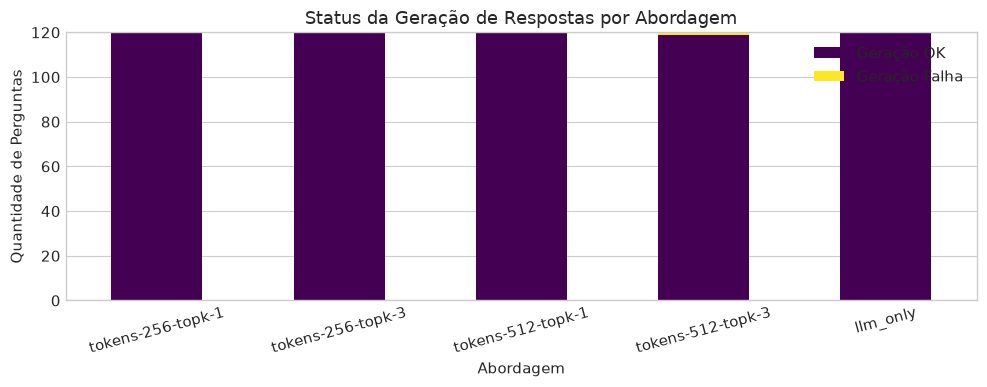

In [59]:
# Análise dos status de geração e recuperação em predictions.jsonl
status_list = []
for app in APPROACHES:
    if app in dfs_predictions:
        df = dfs_predictions[app]
        gen_status = df['generation_status'].value_counts().to_dict() if 'generation_status' in df.columns else {}
        ret_status = df['retrieval_status'].value_counts().to_dict() if 'retrieval_status' in df.columns else {}
        status_list.append({
            "Abordagem": app,
            "Geração OK": gen_status.get("success", gen_status.get("OK", 0)),
            "Geração Falha": sum(v for k, v in gen_status.items() if k not in ["success", "OK"]),
            "Recuperação OK": ret_status.get("success", ret_status.get("OK", 0)),
            "Recuperação N/A / Falha": sum(v for k, v in ret_status.items() if k not in ["success", "OK"])
        })

df_status = pd.DataFrame(status_list)
display(Markdown("### Distribuição dos Status de Execução"))
display(df_status)

# Gráfico de Status das Previsões
fig, ax = plt.subplots(figsize=(10, 4))
df_status.set_index("Abordagem")[["Geração OK", "Geração Falha"]].plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_title("Status da Geração de Respostas por Abordagem")
ax.set_ylabel("Quantidade de Perguntas")
plt.xticks(rotation=15)
plt.show()

## 4. Estatísticas Descritivas das Métricas

Nesta seção, transformamos os dados de `scores.jsonl` em um DataFrame analítico unificado de grão fino (`case_id`, `approach`, `metric`, `score`). As métricas são detectadas **dinamicamente**, sem assumir um conjunto fixo predeterminado.

In [61]:
# Construção da tabela analítica desnormalizada (long format)
score_rows = []

for app in APPROACHES:
    if app not in dfs_scores:
        continue
    df_s = dfs_scores[app]
    for _, row in df_s.iterrows():
        case_id = row.get('case_id')
        scores_dict = row.get('scores', {})
        metric_status = row.get('metric_status', {})
        
        if isinstance(scores_dict, dict):
            for metric_name, val in scores_dict.items():
                # Verificar se o status da métrica indica falha
                m_stat = metric_status.get(metric_name, "success") if isinstance(metric_status, dict) else "success"
                valid_val = None
                if m_stat in ["success", "OK", True] and val is not None and not np.isnan(val):
                    valid_val = float(val)
                
                score_rows.append({
                    "case_id": case_id,
                    "approach": app,
                    "metric": metric_name,
                    "score": valid_val,
                    "status": m_stat
                })

df_scores_long = pd.DataFrame(score_rows)
AVAILABLE_METRICS = df_scores_long['metric'].unique().tolist() if not df_scores_long.empty else []
print(f"Métricas detectadas dinamicamente ({len(AVAILABLE_METRICS)}): {AVAILABLE_METRICS}")

Métricas detectadas dinamicamente (7): ['answer_relevancy', 'bleu', 'rouge1', 'rouge2', 'rouge_l', 'faithfulness', 'context_recall']


In [62]:
# Cálculo das estatísticas descritivas agregadas
def compute_descriptive_stats(df: pd.DataFrame) -> pd.DataFrame:
    stats_list = []
    grouped = df.groupby(['metric', 'approach'])
    for (metric, app), group in grouped:
        valid_scores = group['score'].dropna()
        n = len(valid_scores)
        mean_val = valid_scores.mean() if n > 0 else np.nan
        std_val = valid_scores.std() if n > 1 else np.nan
        median_val = valid_scores.median() if n > 0 else np.nan
        q1_val = valid_scores.quantile(0.25) if n > 0 else np.nan
        q3_val = valid_scores.quantile(0.75) if n > 0 else np.nan
        min_val = valid_scores.min() if n > 0 else np.nan
        max_val = valid_scores.max() if n > 0 else np.nan
        se_val = std_val / np.sqrt(n) if n > 1 else np.nan
        
        stats_list.append({
            "metric": metric,
            "approach": app,
            "n_valid": n,
            "mean": mean_val,
            "std": std_val,
            "se": se_val,
            "median": median_val,
            "q1": q1_val,
            "q3": q3_val,
            "min": min_val,
            "max": max_val
        })
    return pd.DataFrame(stats_list)

df_desc_stats = compute_descriptive_stats(df_scores_long)
display(Markdown("### Tabela Consolidada de Estatísticas Descritivas por Métricas e Abordagem"))
display(df_desc_stats)

### Tabela Consolidada de Estatísticas Descritivas por Métricas e Abordagem

,metric,approach,n_valid,mean,std,se,median,q1,q3,min,max
0,answer_relevancy,llm_only,116,0.5722,0.2885,0.0268,0.6908,0.5099,0.7692,0.0000,0.9218
1,answer_relevancy,tokens-256-topk-1,120,0.5163,0.3402,0.0311,0.6934,0.0000,0.7716,0.0000,0.9368
2,answer_relevancy,tokens-256-topk-3,118,0.6096,0.2745,0.0253,0.7234,0.5551,0.7880,0.0000,1.0000
3,answer_relevancy,tokens-512-topk-1,119,0.5571,0.3313,0.0304,0.7177,0.2674,0.8003,0.0000,1.0000
4,answer_relevancy,tokens-512-topk-3,119,0.5756,0.2936,0.0269,0.6857,0.4495,0.7937,0.0000,1.0000
5,bleu,llm_only,120,0.0327,0.0457,0.0042,0.0161,0.0019,0.0402,0.0000,0.2386
6,bleu,tokens-256-topk-1,120,0.0378,0.0572,0.0052,0.0175,0.0065,0.0350,0.0000,0.2908
7,bleu,tokens-256-topk-3,120,0.0551,0.0963,0.0088,0.0222,0.0028,0.0452,0.0000,0.5292
8,bleu,tokens-512-topk-1,120,0.0465,0.0812,0.0074,0.0186,0.0043,0.0448,0.0000,0.5334
9,bleu,tokens-512-topk-3,119,0.0450,0.0817,0.0075,0.0151,0.0017,0.0434,0.0000,0.4310


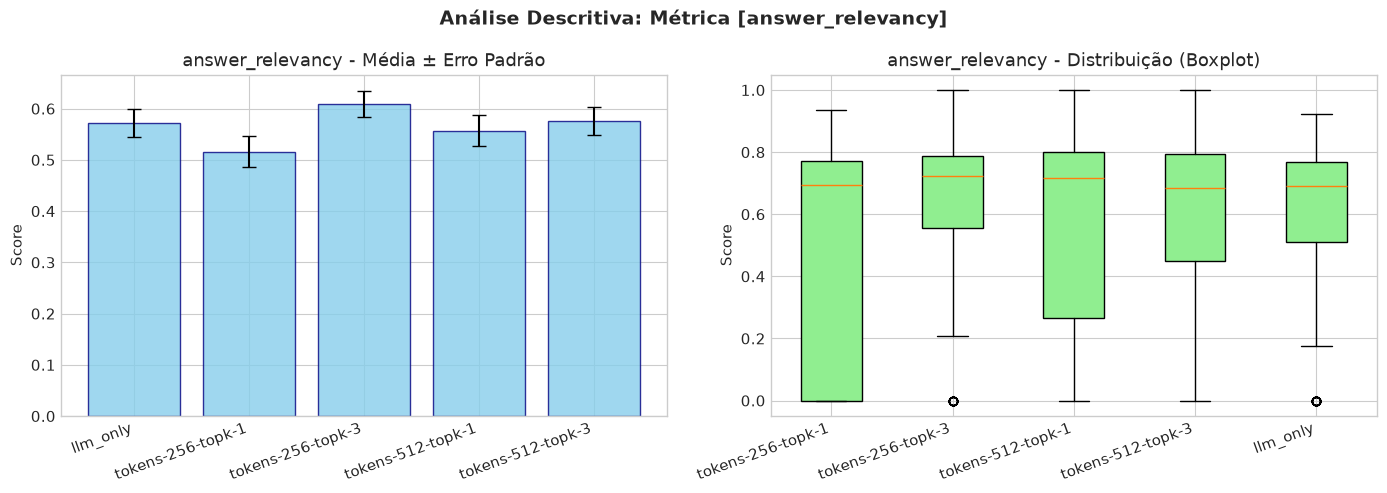

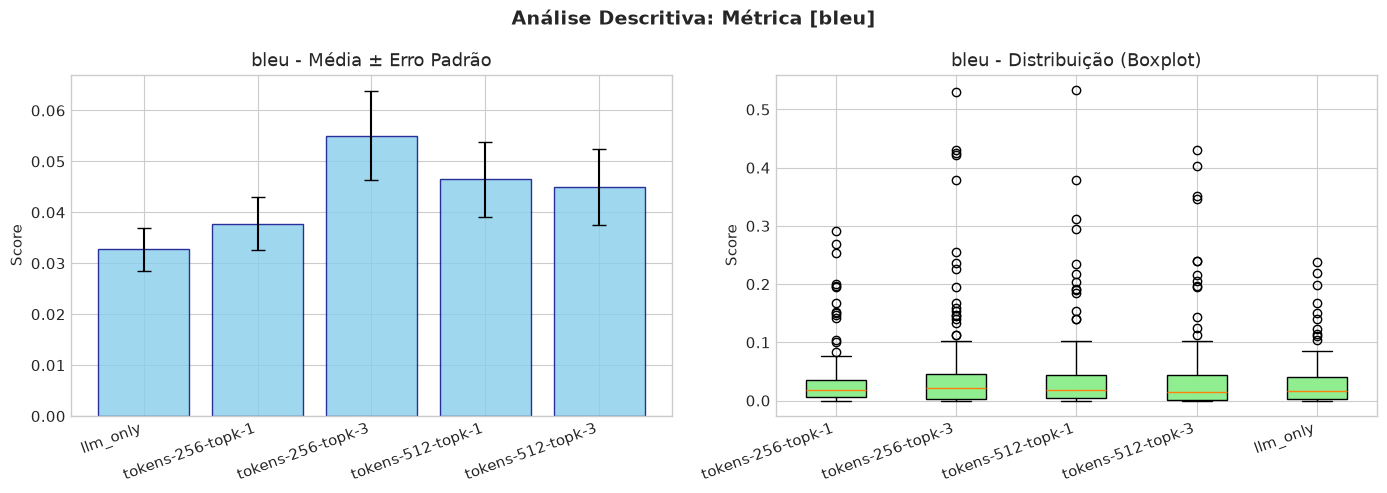

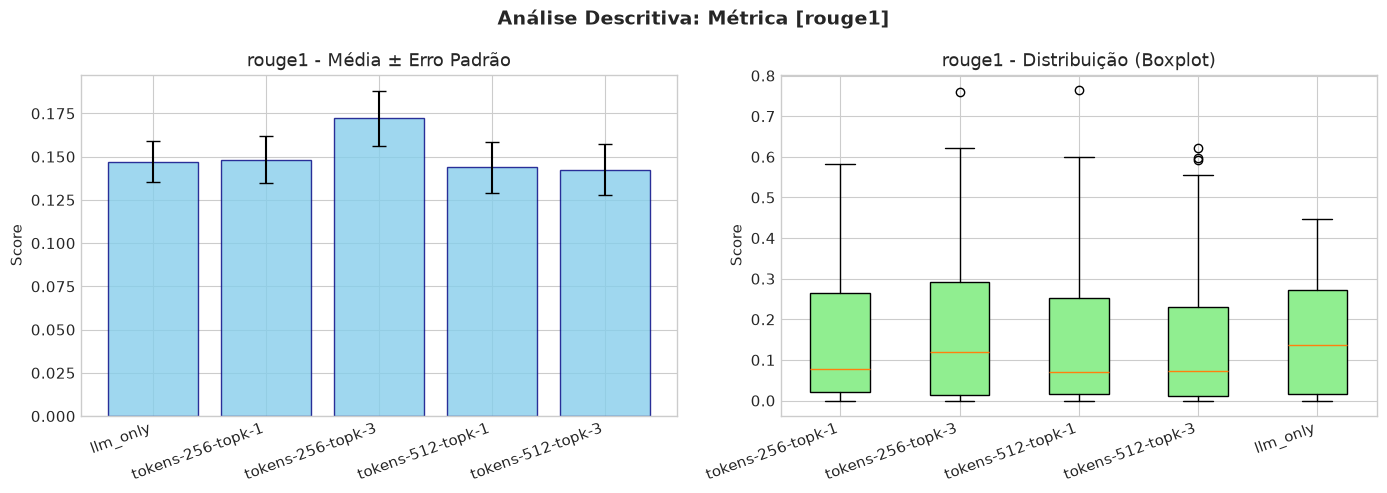

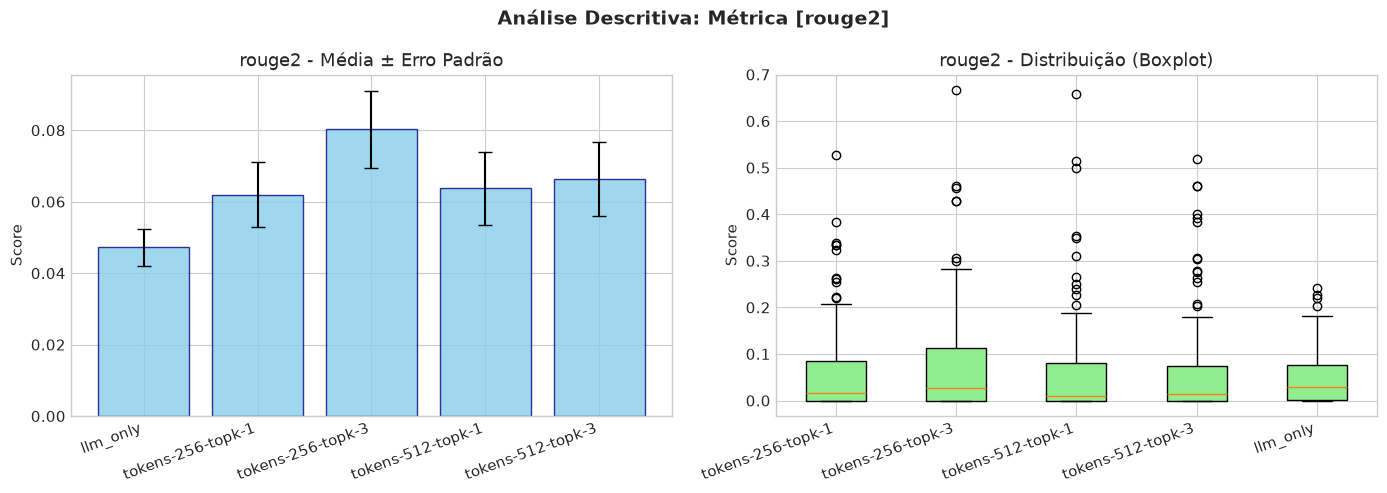

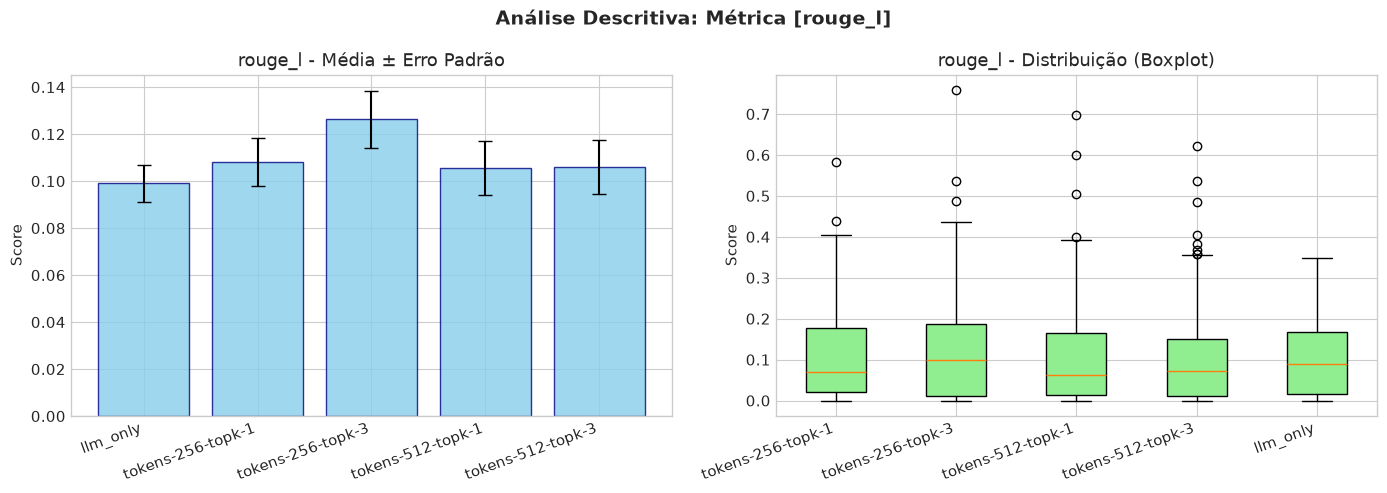

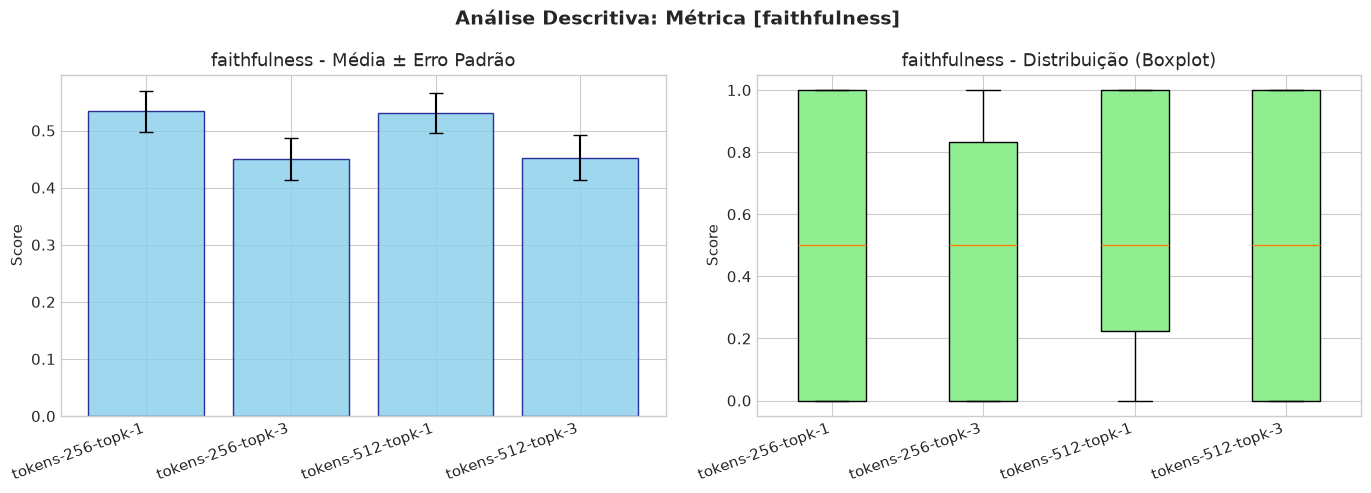

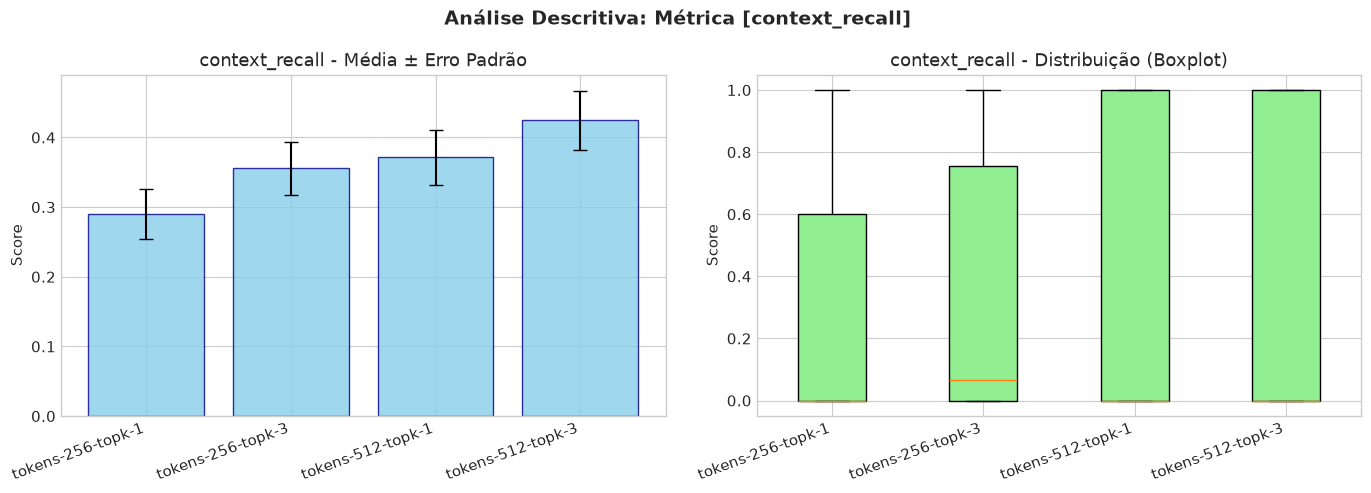

In [66]:
# Visualização 1: Gráficos de Média com Erro-Padrão e Boxplots por Métrica
for metric in AVAILABLE_METRICS:
    df_m = df_scores_long[df_scores_long['metric'] == metric].dropna(subset=['score'])
    df_m_stats = df_desc_stats[df_desc_stats['metric'] == metric]
    
    if df_m.empty:
        continue
        
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Subplot 1: Média com Erro-Padrão
    apps = df_m_stats['approach'].tolist()
    means = df_m_stats['mean'].tolist()
    ses = df_m_stats['se'].tolist()
    
    axes[0].bar(apps, means, yerr=ses, capsize=5, color='skyblue', edgecolor='navy', alpha=0.8)
    axes[0].set_title(f"{metric} - Média ± Erro Padrão")
    axes[0].set_ylabel("Score")
    axes[0].set_xticklabels(apps, rotation=20, ha='right')
    
    # Subplot 2: Boxplot da Distribuição (Correção compatível com todas as versões do Matplotlib)
    labels_to_plot = [app for app in APPROACHES if app in df_m['approach'].values]
    data_to_plot = [df_m[df_m['approach'] == app]['score'].values for app in labels_to_plot]
    
    axes[1].boxplot(data_to_plot, patch_artist=True, boxprops=dict(facecolor='lightgreen'))
    axes[1].set_title(f"{metric} - Distribuição (Boxplot)")
    axes[1].set_ylabel("Score")
    axes[1].set_xticks(range(1, len(labels_to_plot) + 1))
    axes[1].set_xticklabels(labels_to_plot, rotation=20, ha='right')
    
    plt.suptitle(f"Análise Descritiva: Métrica [{metric}]", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 5. Comparação RAG vs. LLM-only

Nesta seção, realizamos a comparação pareada ponto a ponto por `case_id` entre cada uma das 4 configurações RAG e a baseline `llm_only`.
$$\Delta = \text{Score}_{RAG} - \text{Score}_{LLM\text{-}only}$$
*Métricas exclusivas de RAG (como Faithfulness e Context Recall) são ignoradas nesta comparação.*

In [68]:
# Pivotar tabela de scores para formato wide (case_id x approach x metric)
df_pivot = df_scores_long.pivot(index='case_id', columns=['metric', 'approach'], values='score')

rag_vs_llm_summary = []

for metric in AVAILABLE_METRICS:
    # Verificar se llm_only possui dados para esta métrica
    if (metric, 'llm_only') not in df_pivot.columns:
        continue
    
    s_llm = df_pivot[(metric, 'llm_only')]
    
    for rag_app in RAG_APPROACHES:
        if (metric, rag_app) not in df_pivot.columns:
            continue
        
        s_rag = df_pivot[(metric, rag_app)]
        
        # Pareamento exato por case_id ignorando NaNs
        df_pair = pd.DataFrame({'rag': s_rag, 'llm': s_llm}).dropna()
        if df_pair.empty:
            continue
            
        diffs = df_pair['rag'] - df_pair['llm']
        n_pairs = len(diffs)
        wins = (diffs > 1e-6).sum()
        draws = (diffs.abs() <= 1e-6).sum()
        losses = (diffs < -1e-6).sum()
        
        rag_vs_llm_summary.append({
            "Métrica": metric,
            "Config RAG": rag_app,
            "Pares Válidos": n_pairs,
            "Média RAG": df_pair['rag'].mean(),
            "Média LLM-only": df_pair['llm'].mean(),
            "Diferença Média (Delta)": diffs.mean(),
            "Mediana das Diferenças": diffs.median(),
            "Vitórias RAG": wins,
            "Empates": draws,
            "Derrotas RAG": losses,
            "% Vitórias RAG": (wins / n_pairs) * 100 if n_pairs > 0 else 0
        })

df_rag_vs_llm = pd.DataFrame(rag_vs_llm_summary)
display(Markdown("### Resumo Comparativo: RAG vs. LLM-only"))
display(df_rag_vs_llm)

### Resumo Comparativo: RAG vs. LLM-only

,Métrica,Config RAG,Pares Válidos,Média RAG,Média LLM-only,Diferença Média (Delta),Mediana das Diferenças,Vitórias RAG,Empates,Derrotas RAG,% Vitórias RAG
0,answer_relevancy,tokens-256-topk-1,116,0.5123,0.5722,-0.0599,-0.0021,52,5,59,44.8276
1,answer_relevancy,tokens-256-topk-3,114,0.6078,0.5685,0.0393,0.0059,58,3,53,50.8772
2,answer_relevancy,tokens-512-topk-1,115,0.5527,0.5702,-0.0175,0.0032,60,4,51,52.1739
3,answer_relevancy,tokens-512-topk-3,115,0.5758,0.5772,-0.0014,0.0068,60,2,53,52.1739
4,bleu,tokens-256-topk-1,120,0.0378,0.0327,0.0050,0.0016,67,0,53,55.8333
5,bleu,tokens-256-topk-3,120,0.0551,0.0327,0.0223,0.0008,67,0,53,55.8333
6,bleu,tokens-512-topk-1,120,0.0465,0.0327,0.0137,0.0001,62,0,58,51.6667
7,bleu,tokens-512-topk-3,119,0.0450,0.0318,0.0132,0.0008,69,0,50,57.9832
8,rouge1,tokens-256-topk-1,120,0.1482,0.1471,0.0011,-0.0010,56,1,63,46.6667
9,rouge1,tokens-256-topk-3,120,0.1723,0.1471,0.0252,0.0001,61,0,59,50.8333


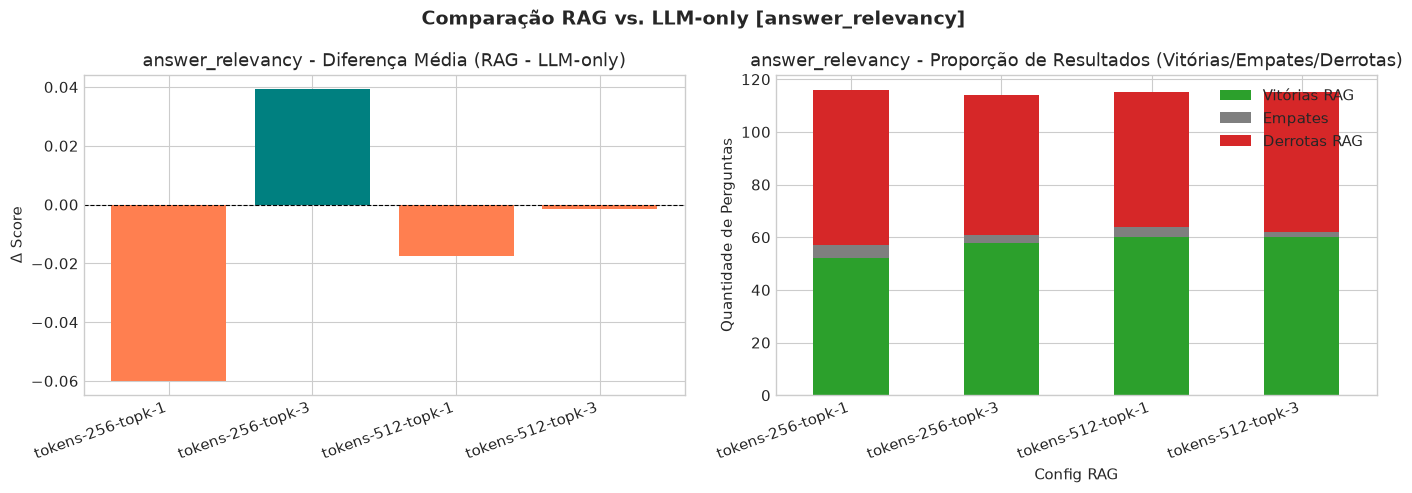

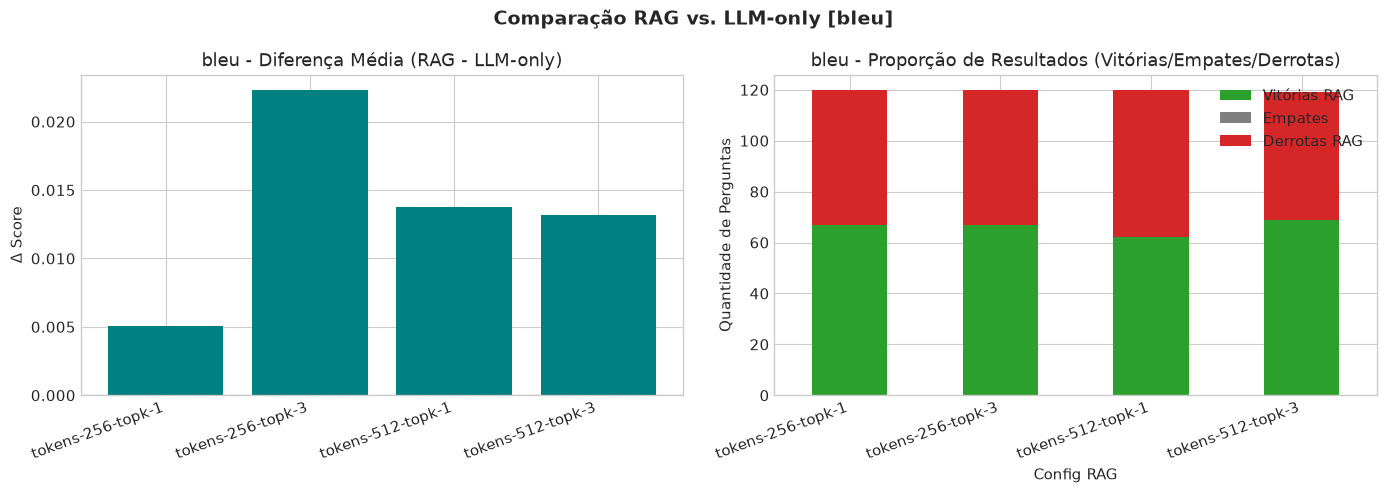

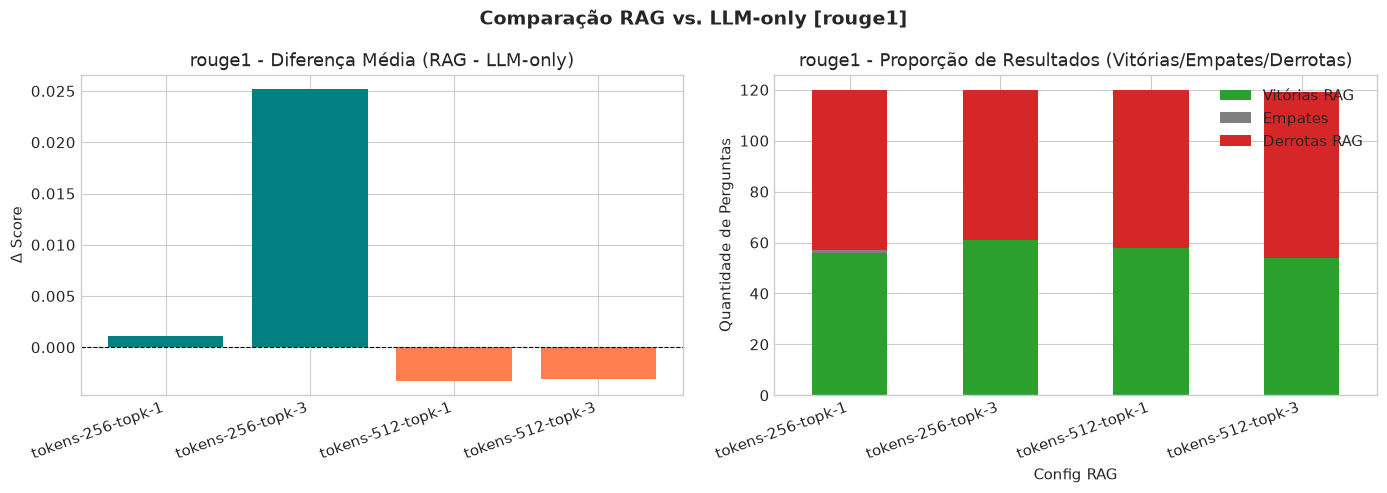

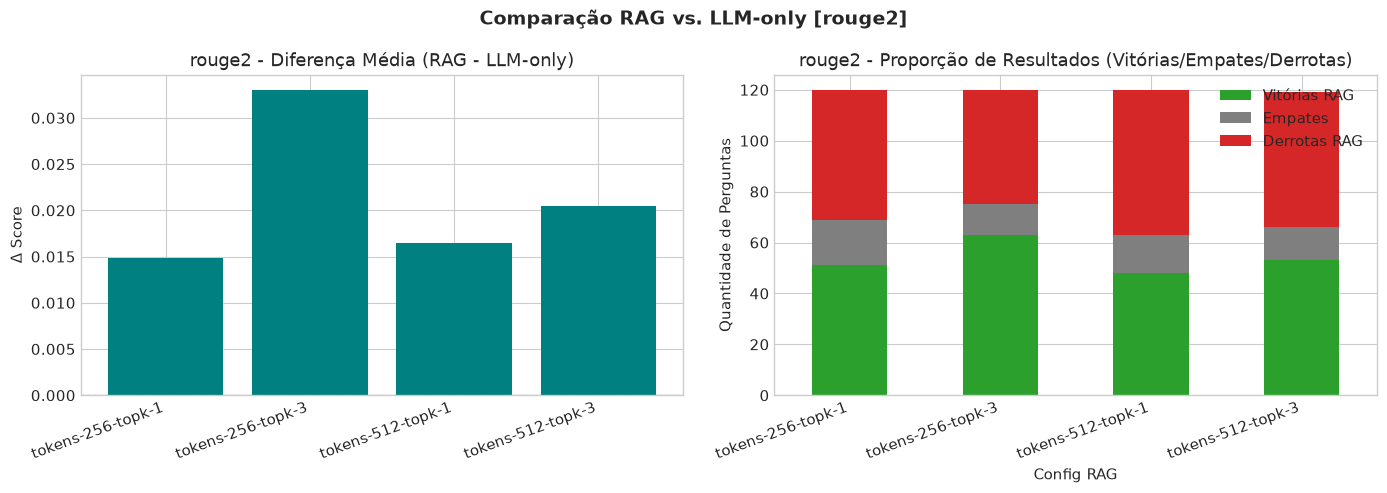

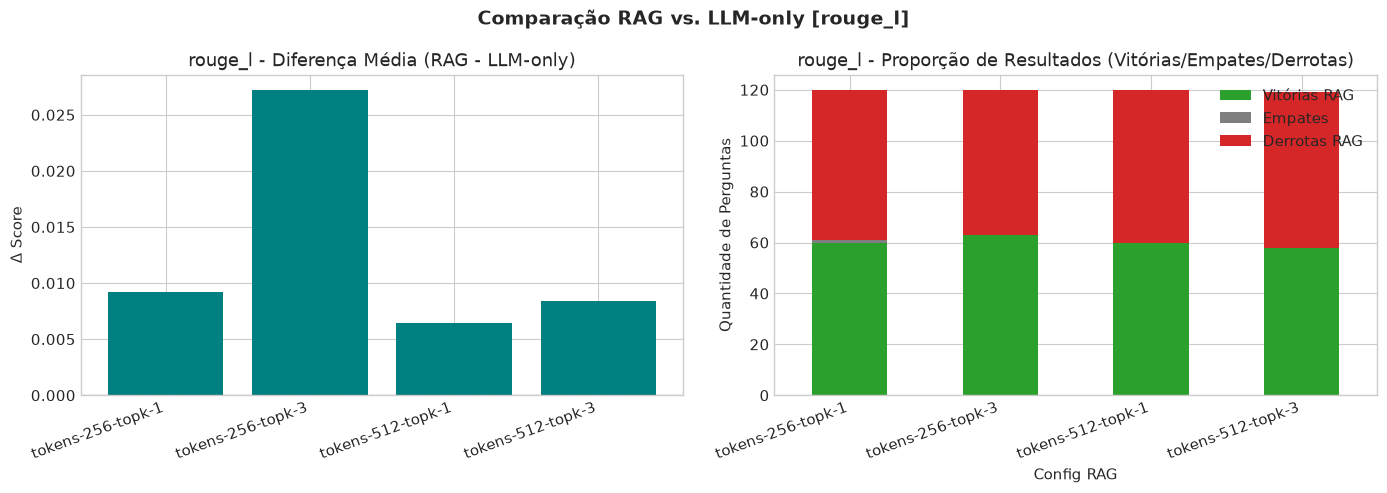

In [69]:
# Visualizações do Comparativo RAG vs LLM-only
metrics_comparable = df_rag_vs_llm['Métrica'].unique().tolist() if not df_rag_vs_llm.empty else []

for metric in metrics_comparable:
    df_sub = df_rag_vs_llm[df_rag_vs_llm['Métrica'] == metric]
    if df_sub.empty:
        continue
        
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Subplot 1: Diferença Média (Delta)
    axes[0].bar(df_sub['Config RAG'], df_sub['Diferença Média (Delta)'], color=['teal' if d >= 0 else 'coral' for d in df_sub['Diferença Média (Delta)']])
    axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
    axes[0].set_title(f"{metric} - Diferença Média (RAG - LLM-only)")
    axes[0].set_ylabel("Δ Score")
    axes[0].set_xticklabels(df_sub['Config RAG'], rotation=20, ha='right')
    
    # Subplot 2: Proporção de Vitórias / Empates / Derrotas
    df_wld = df_sub.set_index('Config RAG')[['Vitórias RAG', 'Empates', 'Derrotas RAG']]
    df_wld.plot(kind='bar', stacked=True, ax=axes[1], color=['#2ca02c', '#7f7f7f', '#d62728'])
    axes[1].set_title(f"{metric} - Proporção de Resultados (Vitórias/Empates/Derrotas)")
    axes[1].set_ylabel("Quantidade de Perguntas")
    axes[1].set_xticklabels(df_sub['Config RAG'], rotation=20, ha='right')
    
    plt.suptitle(f"Comparação RAG vs. LLM-only [{metric}]", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 6. Análise Fatorial $2 \times 2$ das Configurações RAG

Nesta seção, investigamos os efeitos principais e a interação entre os dois fatores do desenho experimental RAG:
- **Fator 1 (Chunk Size)**: 256 vs. 512.
- **Fator 2 (Top-k)**: 1 vs. 3.

### Cálculo da Interação:
$$\text{Interação} = (S_{512, topk3} - S_{512, topk1}) - (S_{256, topk3} - S_{256, topk1})$$
*Interpretação visual: Linhas paralelas no gráfico de interação indicam ausência de interação; linhas não paralelas indicam que o efeito de Top-k depende do Chunk Size.*

In [70]:
factorial_results = []

for metric in AVAILABLE_METRICS:
    # Verificar se todas as 4 configs RAG têm dados para a métrica
    cols = [(metric, app) for app in RAG_APPROACHES if (metric, app) in df_pivot.columns]
    if len(cols) < 4:
        continue
        
    df_fact = df_pivot[cols].dropna()
    if df_fact.empty:
        continue
        
    c256_k1 = df_fact[(metric, 'tokens-256-topk-1')]
    c256_k3 = df_fact[(metric, 'tokens-256-topk-3')]
    c512_k1 = df_fact[(metric, 'tokens-512-topk-1')]
    c512_k3 = df_fact[(metric, 'tokens-512-topk-3')]
    
    # Efeitos principais pareados por pergunta
    effect_chunk = ((c512_k1 + c512_k3) / 2.0) - ((c256_k1 + c256_k3) / 2.0)
    effect_topk = ((c256_k3 + c512_k3) / 2.0) - ((c256_k1 + c512_k1) / 2.0)
    effect_interaction = (c512_k3 - c512_k1) - (c256_k3 - c256_k1)
    
    factorial_results.append({
        "Métrica": metric,
        "N Perguntas": len(df_fact),
        "Média (256, k=1)": c256_k1.mean(),
        "Média (256, k=3)": c256_k3.mean(),
        "Média (512, k=1)": c512_k1.mean(),
        "Média (512, k=3)": c512_k3.mean(),
        "Efeito Principal Chunk (512 - 256)": effect_chunk.mean(),
        "Efeito Principal Top-k (3 - 1)": effect_topk.mean(),
        "Efeito de Interação Estimado": effect_interaction.mean()
    })

df_factorial = pd.DataFrame(factorial_results)
display(Markdown("### Estimativa dos Efeitos Fatoriais $2 \times 2$"))
display(df_factorial)

### Estimativa dos Efeitos Fatoriais $2 	imes 2$

,Métrica,N Perguntas,"Média (256, k=1)","Média (256, k=3)","Média (512, k=1)","Média (512, k=3)",Efeito Principal Chunk (512 - 256),Efeito Principal Top-k (3 - 1),Efeito de Interação Estimado
0,answer_relevancy,116,0.5128,0.6085,0.5515,0.5855,0.0078,0.0648,-0.0617
1,bleu,119,0.0360,0.0551,0.0465,0.0450,0.0002,0.0088,-0.0206
2,rouge1,119,0.1453,0.1729,0.1440,0.1423,-0.0159,0.0129,-0.0293
3,rouge2,119,0.0593,0.0803,0.0637,0.0663,-0.0048,0.0118,-0.0184
4,rouge_l,119,0.1067,0.1264,0.1055,0.1060,-0.0109,0.0101,-0.0192
5,faithfulness,116,0.5399,0.4572,0.5354,0.4485,-0.0066,-0.0848,-0.0043
6,context_recall,117,0.2816,0.3563,0.3660,0.4244,0.0762,0.0666,-0.0163


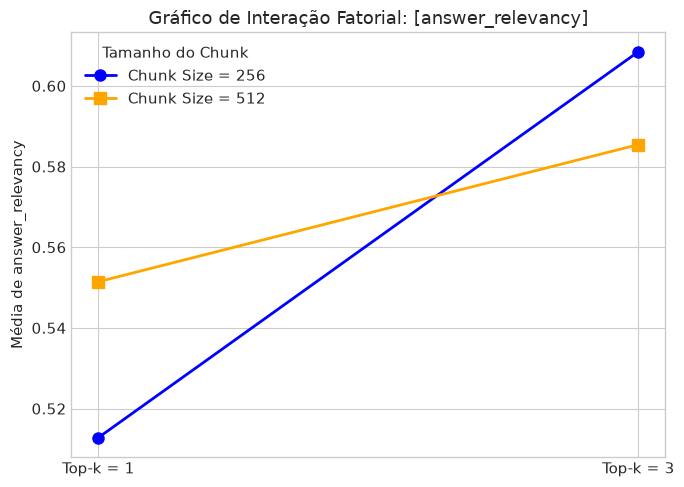

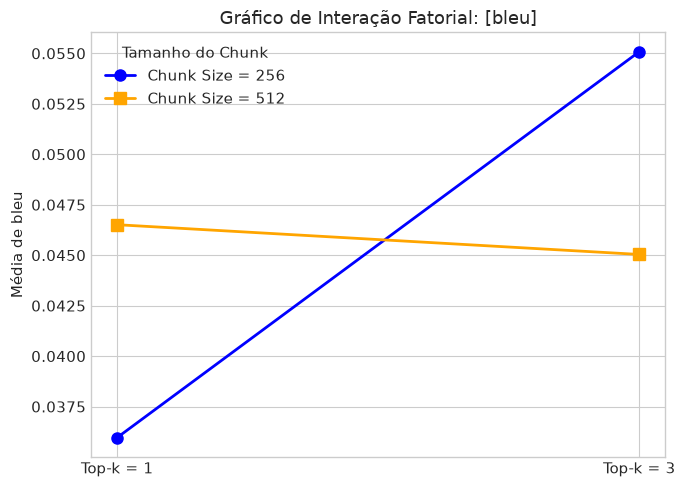

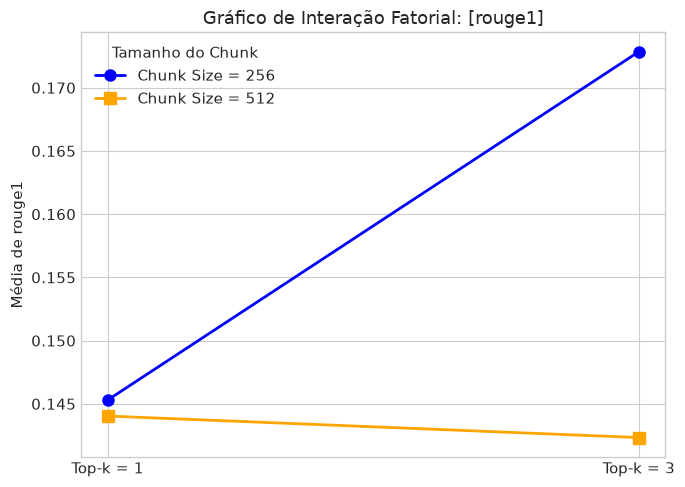

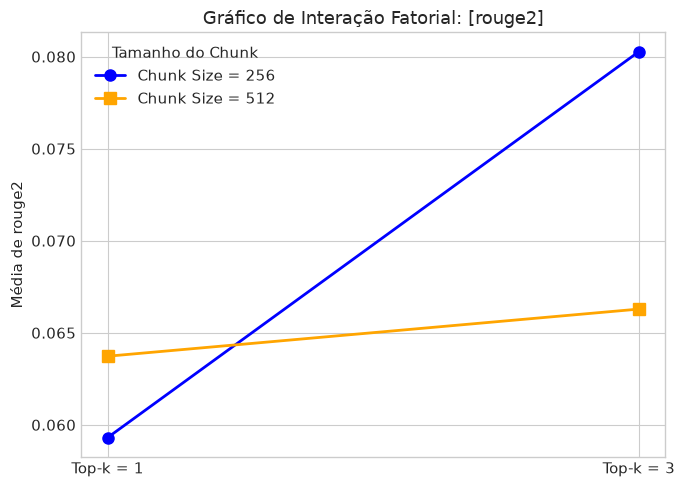

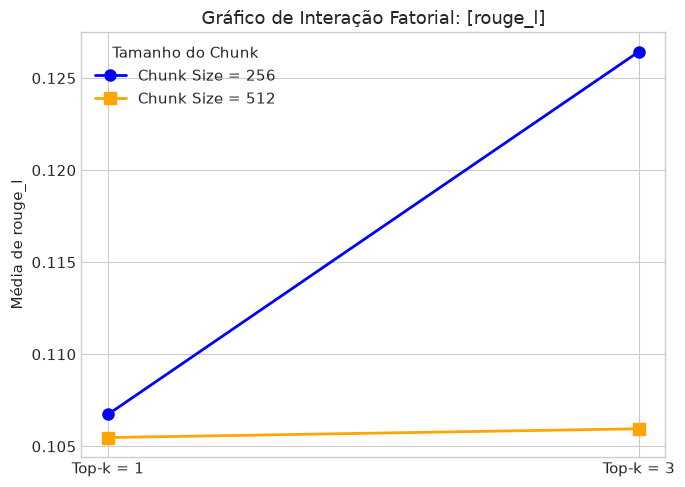

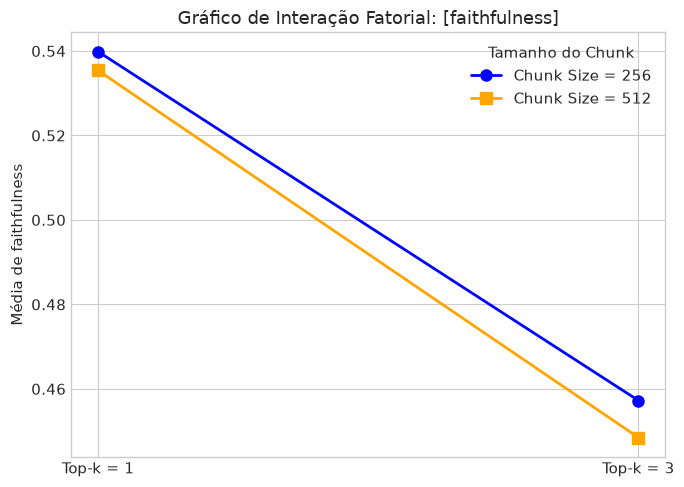

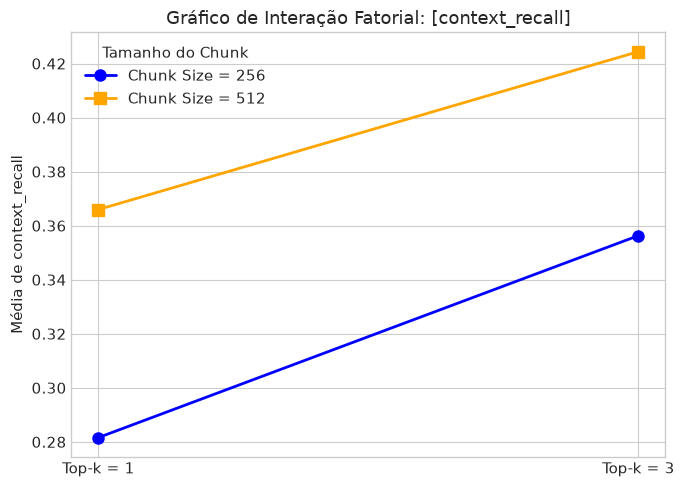

In [71]:
# Gráficos de Interação Fatorial
for metric in AVAILABLE_METRICS:
    df_sub = df_factorial[df_factorial['Métrica'] == metric]
    if df_sub.empty:
        continue
        
    row = df_sub.iloc[0]
    
    fig, ax = plt.subplots(figsize=(7, 5))
    
    # Pontos do gráfico de interação
    topk_vals = ['Top-k = 1', 'Top-k = 3']
    chunk_256 = [row['Média (256, k=1)'], row['Média (256, k=3)']]
    chunk_512 = [row['Média (512, k=1)'], row['Média (512, k=3)']]
    
    ax.plot(topk_vals, chunk_256, marker='o', linewidth=2, markersize=8, label='Chunk Size = 256', color='blue')
    ax.plot(topk_vals, chunk_512, marker='s', linewidth=2, markersize=8, label='Chunk Size = 512', color='orange')
    
    ax.set_title(f"Gráfico de Interação Fatorial: [{metric}]")
    ax.set_ylabel(f"Média de {metric}")
    ax.legend(title="Tamanho do Chunk")
    plt.tight_layout()
    plt.show()

## 7. Análise por Pergunta

Nesta seção, analisamos o comportamento individual de cada pergunta (`case_id`), identificando casos onde RAG supera significativamente o LLM-only, casos em que o LLM-only é superior, variações extremas entre abordagens e falhas generalizadas.

### Tabela por Pergunta - Métrica Selecionada: `answer_relevancy` (Primeiras 10 linhas)

approach,llm_only,tokens-256-topk-1,tokens-256-topk-3,tokens-512-topk-1,tokens-512-topk-3,user_input,diff_tokens-256-topk-1_vs_llm,diff_tokens-256-topk-3_vs_llm,diff_tokens-512-topk-1_vs_llm,diff_tokens-512-topk-3_vs_llm
case_id,,,,,,,,,,
qa_2024_0001,0.8027,0.9368,0.5944,0.8127,0.7120,Quem está obrigado a apresentar a Declaração d...,0.1341,-0.2084,0.0100,-0.0907
qa_2024_0002,0.7662,0.7685,0.6016,0.7775,0.7891,Pessoa física desobrigada pode apresentar a De...,0.0023,-0.1647,0.0113,0.0228
qa_2024_0003,0.6767,0.6769,0.7301,0.6754,0.6782,Contribuinte que é titular ou sócio de empresa...,0.0002,0.0534,-0.0013,0.0015
qa_2024_0004,0.5719,0.7362,0.0000,0.0000,0.5807,"Contribuinte, que participou de quadro societá...",0.1643,-0.5719,-0.5719,0.0088
qa_2024_0005,0.7896,0.0000,0.0000,0.7944,0.0000,Contribuinte que constou como responsável pera...,-0.7896,-0.7896,0.0047,-0.7896
qa_2024_0006,0.0000,0.8207,0.8195,0.7630,0.0000,Existe limite de idade para a obrigatoriedade ...,0.8207,0.8195,0.7630,0.0000
qa_2024_0007,0.8103,0.6615,0.6476,0.6615,0.6615,Para verificação da obrigatoriedade de apresen...,-0.1489,-0.1627,-0.1489,-0.1489
qa_2024_0008,0.8264,0.0000,0.0000,0.8352,0.6449,A posse ou a propriedade de bens e direitos re...,-0.8264,-0.8264,0.0088,-0.1814
qa_2024_0009,0.6930,0.0000,0.6998,0.6077,0.6632,O contribuinte deve apresentar uma Declaração ...,-0.6930,0.0068,-0.0853,-0.0298


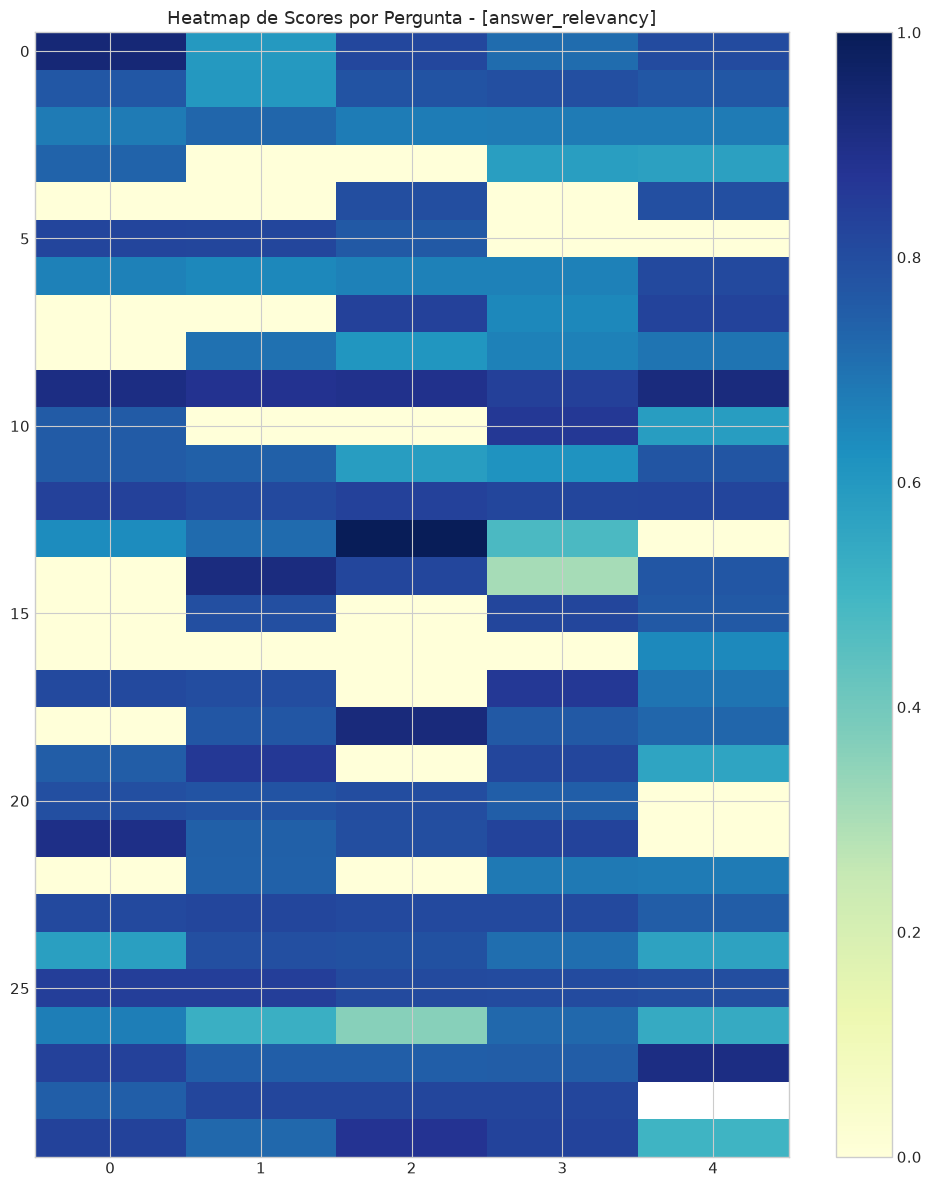

In [72]:
# Construção do DataFrame de análise por pergunta para uma métrica selecionada
SELECTED_METRIC = AVAILABLE_METRICS[0] if AVAILABLE_METRICS else "answer_relevancy"

# Filtrar dados para a métrica selecionada
df_metric_pivot = df_scores_long[df_scores_long['metric'] == SELECTED_METRIC].pivot(index='case_id', columns='approach', values='score')

# Adicionar texto de entrada da pergunta se disponível
if 'llm_only' in dfs_predictions and 'user_input' in dfs_predictions['llm_only'].columns:
    user_inputs = dfs_predictions['llm_only'].set_index('case_id')['user_input'].to_dict()
    df_metric_pivot['user_input'] = df_metric_pivot.index.map(user_inputs)

# Calcular diferenças RAG - LLM-only por pergunta
if 'llm_only' in df_metric_pivot.columns:
    for rag_app in RAG_APPROACHES:
        if rag_app in df_metric_pivot.columns:
            df_metric_pivot[f'diff_{rag_app}_vs_llm'] = df_metric_pivot[rag_app] - df_metric_pivot['llm_only']

display(Markdown(f"### Tabela por Pergunta - Métrica Selecionada: `{SELECTED_METRIC}` (Primeiras 10 linhas)"))
display(df_metric_pivot.head(10))

# Heatmap dos Scores por Pergunta e Abordagem
fig, ax = plt.subplots(figsize=(10, 12))
cols_to_plot = [app for app in APPROACHES if app in df_metric_pivot.columns]
if HAS_SEABORN and not df_metric_pivot[cols_to_plot].empty:
    sns.heatmap(df_metric_pivot[cols_to_plot].head(30), annot=True, fmt=".2f", cmap="YlGnBu", ax=ax)
    ax.set_title(f"Heatmap de Scores por Pergunta (Top 30 Cases) - [{SELECTED_METRIC}]")
    plt.show()
else:
    im = ax.imshow(df_metric_pivot[cols_to_plot].head(30).values, aspect='auto', cmap='YlGnBu')
    plt.colorbar(im)
    ax.set_title(f"Heatmap de Scores por Pergunta - [{SELECTED_METRIC}]")
    plt.show()

## 8. Análise do Processo de Recuperação

Nesta seção, exploramos o comportamento da etapa de recuperação de contextos a partir dos dados de `retrieval.jsonl`.

In [73]:
# Consolidação dos dados de recuperação por configuração RAG
retrieval_records = []

for app in RAG_APPROACHES:
    if app not in dfs_retrieval:
        continue
    df_r = dfs_retrieval[app]
    
    for _, row in df_r.iterrows():
        case_id = row.get('case_id')
        chunks = row.get('retrieved_chunks', [])
        contexts = row.get('retrieved_contexts', [])
        lat = row.get('latency_seconds', np.nan)
        status = row.get('status', 'UNKNOWN')
        
        n_chunks = len(chunks) if isinstance(chunks, list) else 0
        n_contexts = len(contexts) if isinstance(contexts, list) else 0
        
        # Contagem de caracteres e tokens
        char_count = sum(len(c) for c in contexts) if isinstance(contexts, list) else 0
        token_count = 0
        distances = []
        if isinstance(chunks, list):
            for ch in chunks:
                if isinstance(ch, dict):
                    meta = ch.get('metadata', {})
                    token_count += meta.get('token_count', 0)
                    if 'distance' in ch:
                        distances.append(ch['distance'])
        
        retrieval_records.append({
            "case_id": case_id,
            "approach": app,
            "n_chunks": n_chunks,
            "n_contexts": n_contexts,
            "char_count": char_count,
            "token_count": token_count if token_count > 0 else np.nan,
            "latency_seconds": lat,
            "mean_distance": np.mean(distances) if distances else np.nan,
            "status": status
        })

df_retrieval_summary = pd.DataFrame(retrieval_records)

# Tabela agregada de recuperação por abordagem
df_ret_agg = df_retrieval_summary.groupby('approach').agg({
    'n_chunks': ['mean', 'median', 'std', 'min', 'max'],
    'char_count': ['mean', 'median', 'std'],
    'latency_seconds': ['mean', 'median', 'std']
})

display(Markdown("### Estatísticas Agregadas do Processo de Recuperação"))
display(df_ret_agg)

### Estatísticas Agregadas do Processo de Recuperação

n_chunks                       char_count            \
                      mean median    std min max       mean    median   
approach                                                                
tokens-256-topk-1   1.0000 1.0000 0.0000   1   1   930.0500  932.0000   
tokens-256-topk-3   3.0000 3.0000 0.0000   3   3  2802.9667 2822.5000   
tokens-512-topk-1   1.0000 1.0000 0.0000   1   1  1893.5583 1895.0000   
tokens-512-topk-3   3.0000 3.0000 0.0000   3   3  5598.1000 5641.5000   

                           latency_seconds                
                       std            mean median    std  
approach                                                  
tokens-256-topk-1  78.5572          0.1556 0.0347 0.6561  
tokens-256-topk-3 148.7937          0.0258 0.0252 0.0053  
tokens-512-topk-1 133.9224          0.0257 0.0241 0.0078  
tokens-512-topk-3 259.6558          0.0255 0.0246 0.0058

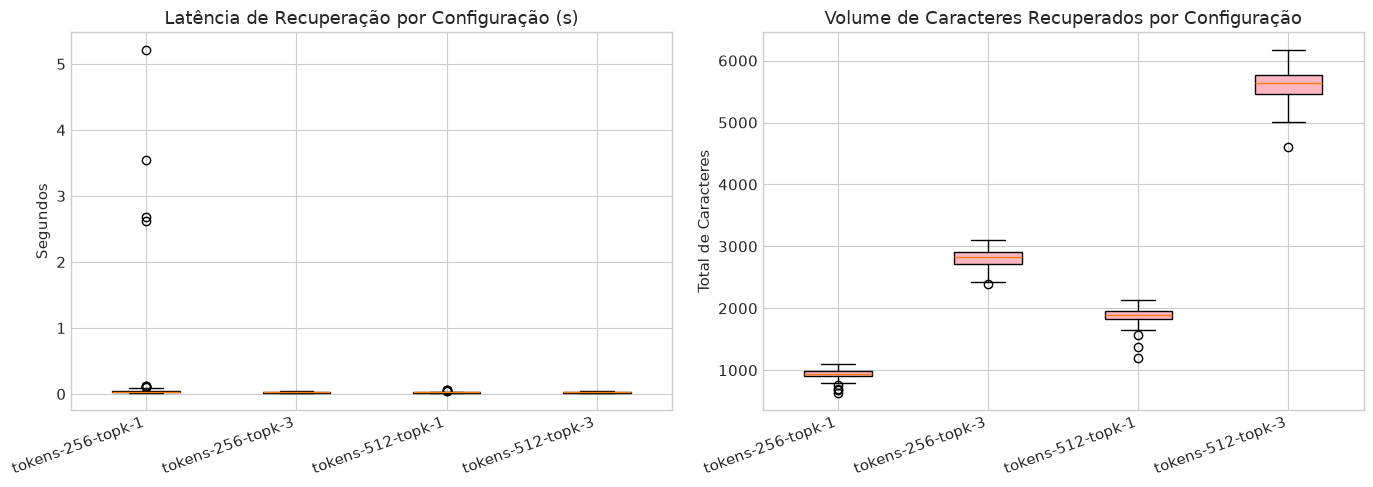

In [76]:
# Gráficos da Recuperação
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot da Latência de Recuperação
data_lat = [df_retrieval_summary[df_retrieval_summary['approach'] == app]['latency_seconds'].dropna() for app in RAG_APPROACHES]
axes[0].boxplot(data_lat,  patch_artist=True, boxprops=dict(facecolor='lightblue'))
axes[0].set_title("Latência de Recuperação por Configuração (s)")
axes[0].set_ylabel("Segundos")
axes[0].set_xticklabels(RAG_APPROACHES, rotation=20, ha='right')

# Boxplot do Volume de Caracteres Recuperados
data_chars = [df_retrieval_summary[df_retrieval_summary['approach'] == app]['char_count'].dropna() for app in RAG_APPROACHES]
axes[1].boxplot(data_chars,  patch_artist=True, boxprops=dict(facecolor='lightpink'))
axes[1].set_title("Volume de Caracteres Recuperados por Configuração")
axes[1].set_ylabel("Total de Caracteres")
axes[1].set_xticklabels(RAG_APPROACHES, rotation=20, ha='right')

plt.tight_layout()
plt.show()

## 9. Relação entre Recuperação e Qualidade

Nesta seção, investigamos se existe associação (via Correlação de Spearman) entre variáveis da etapa de recuperação (ex: número de chunks, total de caracteres, latência) e a qualidade das respostas geradas.

*Aviso Importante: Correlação estatística indica associação monotônica, mas NÃO implica relação de causalidade direta.*

In [77]:
# Cruzar dados de recuperação com métricas de qualidade
df_ret_quality = pd.merge(df_retrieval_summary, df_scores_long, on=['case_id', 'approach']).dropna(subset=['score'])

corr_results = []
ret_vars = ['n_chunks', 'char_count', 'latency_seconds']

for metric in AVAILABLE_METRICS:
    df_m = df_ret_quality[df_ret_quality['metric'] == metric]
    for var in ret_vars:
        valid_data = df_m[[var, 'score']].dropna()
        if len(valid_data) > 5:
            rho, pval = stats.spearmanr(valid_data[var], valid_data['score'])
            corr_results.append({
                "Métrica Qualidade": metric,
                "Variável Recuperação": var,
                "N Observações": len(valid_data),
                "Spearman Rho": rho,
                "p-valor": pval
            })

df_correlations = pd.DataFrame(corr_results)
display(Markdown("### Correlação de Spearman entre Recuperação e Qualidade"))
display(df_correlations)

### Correlação de Spearman entre Recuperação e Qualidade

,Métrica Qualidade,Variável Recuperação,N Observações,Spearman Rho,p-valor
0,answer_relevancy,n_chunks,476,0.0415,0.3659
1,answer_relevancy,char_count,476,0.0595,0.1954
2,answer_relevancy,latency_seconds,476,-0.0717,0.1182
3,bleu,n_chunks,479,-0.0122,0.7900
4,bleu,char_count,479,-0.0670,0.1433
5,bleu,latency_seconds,479,-0.0479,0.2954
6,rouge1,n_chunks,479,0.0201,0.6605
7,rouge1,char_count,479,-0.0254,0.5786
8,rouge1,latency_seconds,479,-0.1024,0.0250
9,rouge2,n_chunks,479,0.0615,0.1787


## 10. Análise de Latência

Nesta seção, analisamos o perfil de tempo de resposta: latência de recuperação, latência de geração e tempo total por abordagem.

### Estatísticas Descritivas de Latência (Segundos)

retrieval_latency               generation_latency         \
                               mean median    std               mean median   
approach                                                                      
llm_only                        NaN    NaN    NaN            76.6117 1.8747   
tokens-256-topk-1            0.1556 0.0347 0.6561            23.8008 0.8022   
tokens-256-topk-3            0.0258 0.0252 0.0053            59.0032 1.0546   
tokens-512-topk-1            0.0257 0.0241 0.0078            59.3575 1.0852   
tokens-512-topk-3            0.0255 0.0246 0.0058            71.9754 1.2612   

                           total_latency                  
                       std          mean median      std  
approach                                                  
llm_only          151.7191       76.6117 1.8747 151.7191  
tokens-256-topk-1  88.9978       23.9564 0.8422  89.1629  
tokens-256-topk-3 136.6161       59.0291 1.0733 136.6160  
tokens-512-topk-1 137.2667       59.3833 1.1165 137.2664  
tokens-512-topk-3 147.3955       72.0009 1.2861 147.3953

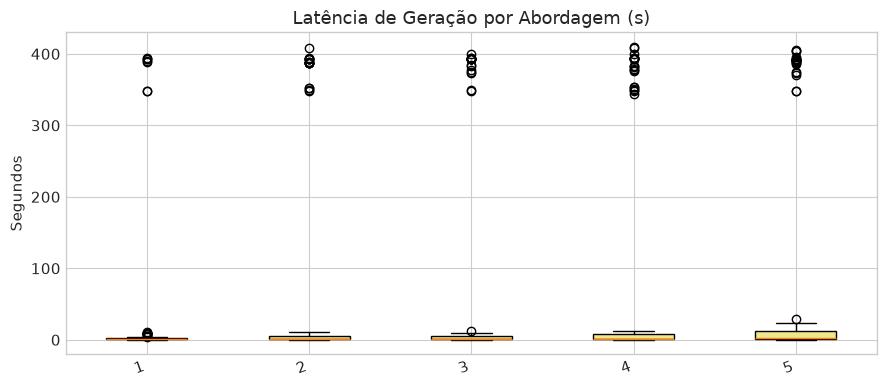

In [79]:
latency_records = []

for app in APPROACHES:
    if app not in dfs_predictions:
        continue
    df_p = dfs_predictions[app]
    for _, row in df_p.iterrows():
        ret_lat = row.get('retrieval_latency_seconds', np.nan)
        gen_lat = row.get('generation_latency_seconds', np.nan)
        
        # Converter valores inválidos ou zerados indevidos
        ret_lat = float(ret_lat) if ret_lat is not None and not np.isnan(ret_lat) else np.nan
        gen_lat = float(gen_lat) if gen_lat is not None and not np.isnan(gen_lat) else np.nan
        
        total_lat = (ret_lat if not np.isnan(ret_lat) else 0.0) + (gen_lat if not np.isnan(gen_lat) else 0.0)
        if np.isnan(gen_lat):
            total_lat = np.nan
            
        latency_records.append({
            "case_id": row.get('case_id'),
            "approach": app,
            "retrieval_latency": ret_lat,
            "generation_latency": gen_lat,
            "total_latency": total_lat
        })

df_latency = pd.DataFrame(latency_records)

df_lat_stats = df_latency.groupby('approach').agg({
    'retrieval_latency': ['mean', 'median', 'std'],
    'generation_latency': ['mean', 'median', 'std'],
    'total_latency': ['mean', 'median', 'std']
})

display(Markdown("### Estatísticas Descritivas de Latência (Segundos)"))
display(df_lat_stats)

# Gráfico de Latência de Geração
fig, ax = plt.subplots(figsize=(9, 4))
data_gen_lat = [df_latency[df_latency['approach'] == app]['generation_latency'].dropna() for app in APPROACHES]
ax.boxplot(data_gen_lat, patch_artist=True, boxprops=dict(facecolor='khaki'))
ax.set_title("Latência de Geração por Abordagem (s)")
ax.set_ylabel("Segundos")
plt.xticks(rotation=20, ha='right')
plt.show()

## 11. Testes Estatísticos

Nesta seção, aplicamos testes não-paramétricos de hipótese, cálculo do tamanho de efeito ($Cohen's\ d_z$), intervalos de confiança via Bootstrap e correção para múltiplas comparações (Holm-Bonferroni).

### Testes Aplicados:
1. **Wilcoxon Signed-Rank Test**: Comparações pareadas (RAG vs. LLM-only e post-hoc).
2. **Friedman Test**: Comparação global entre as 4 configurações RAG sobre amostras completas.
3. **Correction de Holm**: Ajuste de p-valores para controle de FWER.
4. **Bootstrap (95% CI)**: Estimativa robusta não-paramétrica dos intervalos de confiança da diferença média pareada.

In [80]:
# Função auxiliar para Bootstrap de Intervalo de Confiança 95%
def bootstrap_ci_mean_diff(diffs: np.ndarray, n_boot: int = 5000, ci: float = 95.0, seed: int = RANDOM_SEED) -> Tuple[float, float]:
    rng = np.random.default_rng(seed)
    boot_means = np.zeros(n_boot)
    n = len(diffs)
    for i in range(n_boot):
        sample = rng.choice(diffs, size=n, replace=True)
        boot_means[i] = np.mean(sample)
    lower = np.percentile(boot_means, (100 - ci) / 2.0)
    upper = np.percentile(boot_means, 100 - ((100 - ci) / 2.0))
    return lower, upper

# Função para calcular Cohen's dz para amostras pareadas
def cohen_dz(diffs: np.ndarray) -> float:
    sd = np.std(diffs, ddof=1)
    if sd == 0 or np.isnan(sd):
        return 0.0
    return np.mean(diffs) / sd

# Função para Correção de Holm-Bonferroni
def holm_bonferroni_correction(p_values: List[float]) -> List[float]:
    m = len(p_values)
    indexed_p = sorted(enumerate(p_values), key=lambda x: x[1])
    adjusted_p = [0.0] * m
    cum_max = 0.0
    for rank, (original_idx, p_val) in enumerate(indexed_p):
        adj = p_val * (m - rank)
        cum_max = max(cum_max, adj)
        adjusted_p[original_idx] = min(cum_max, 1.0)
    return adjusted_p

In [81]:
# 11.1 Testes de Wilcoxon: RAG vs. LLM-only
wilcoxon_results = []

for metric in AVAILABLE_METRICS:
    if (metric, 'llm_only') not in df_pivot.columns:
        continue
    s_llm = df_pivot[(metric, 'llm_only')]
    
    for rag_app in RAG_APPROACHES:
        if (metric, rag_app) not in df_pivot.columns:
            continue
        s_rag = df_pivot[(metric, rag_app)]
        df_pair = pd.DataFrame({'rag': s_rag, 'llm': s_llm}).dropna()
        diffs = (df_pair['rag'] - df_pair['llm']).values
        n_pairs = len(diffs)
        
        if n_pairs >= 5 and not np.all(diffs == 0):
            stat, pval = stats.wilcoxon(diffs, zero_method='pratt')
            dz = cohen_dz(diffs)
            ci_low, ci_high = bootstrap_ci_mean_diff(diffs, n_boot=5000)
            
            wilcoxon_results.append({
                "Métrica": metric,
                "Config RAG": rag_app,
                "N Pares": n_pairs,
                "Diferença Média": np.mean(diffs),
                "CI 95% Inferior": ci_low,
                "CI 95% Superior": ci_high,
                "Estatística W": stat,
                "p-valor Original": pval,
                "Cohen dz": dz
            })

df_wilcoxon = pd.DataFrame(wilcoxon_results)
if not df_wilcoxon.empty:
    df_wilcoxon['p-valor Ajustado (Holm)'] = holm_bonferroni_correction(df_wilcoxon['p-valor Original'].tolist())

display(Markdown("### Resultados do Teste de Wilcoxon (RAG vs. LLM-only)"))
display(df_wilcoxon)

### Resultados do Teste de Wilcoxon (RAG vs. LLM-only)

,Métrica,Config RAG,N Pares,Diferença Média,CI 95% Inferior,CI 95% Superior,Estatística W,p-valor Original,Cohen dz,p-valor Ajustado (Holm)
0,answer_relevancy,tokens-256-topk-1,116,-0.0599,-0.1466,0.0288,2974.0000,0.2569,-0.1274,1.0000
1,answer_relevancy,tokens-256-topk-3,114,0.0393,-0.0350,0.1119,3005.0000,0.4461,0.0966,1.0000
2,answer_relevancy,tokens-512-topk-1,115,-0.0175,-0.0969,0.0634,3329.0000,0.9978,-0.0390,1.0000
3,answer_relevancy,tokens-512-topk-3,115,-0.0014,-0.0752,0.0755,3308.0000,0.9433,-0.0034,1.0000
4,bleu,tokens-256-topk-1,120,0.0050,-0.0067,0.0168,3242.0000,0.3096,0.0763,1.0000
5,bleu,tokens-256-topk-3,120,0.0223,0.0052,0.0407,3034.0000,0.1186,0.2215,1.0000
6,bleu,tokens-512-topk-1,120,0.0137,-0.0023,0.0313,3411.0000,0.5663,0.1472,1.0000
7,bleu,tokens-512-topk-3,119,0.0132,-0.0016,0.0294,3169.0000,0.2876,0.1535,1.0000
8,rouge1,tokens-256-topk-1,120,0.0011,-0.0322,0.0340,3574.0000,0.8844,0.0060,1.0000
9,rouge1,tokens-256-topk-3,120,0.0252,-0.0113,0.0601,3335.0000,0.4398,0.1249,1.0000


In [82]:
# 11.2 Teste de Friedman (Comparação Global entre as 4 Configurações RAG)
friedman_results = []

for metric in AVAILABLE_METRICS:
    cols = [(metric, app) for app in RAG_APPROACHES if (metric, app) in df_pivot.columns]
    if len(cols) < 4:
        continue
    
    # Exigir amostras completas em todas as 4 abordagens RAG
    df_complete = df_pivot[cols].dropna()
    if len(df_complete) >= 5:
        data_arrays = [df_complete[col].values for col in cols]
        stat, pval = stats.friedmanchisquare(*data_arrays)
        friedman_results.append({
            "Métrica": metric,
            "N Perguntas Completas": len(df_complete),
            "Estatística Friedman (Q)": stat,
            "p-valor": pval,
            "Significativo (alpha=0.05)": pval < 0.05
        })

df_friedman = pd.DataFrame(friedman_results)
display(Markdown("### Resultados do Teste de Friedman (4 Configurações RAG)"))
display(df_friedman)

### Resultados do Teste de Friedman (4 Configurações RAG)

,Métrica,N Perguntas Completas,Estatística Friedman (Q),p-valor,Significativo (alpha=0.05)
0,answer_relevancy,116,1.6450,0.6492,False
1,bleu,119,1.3082,0.7272,False
2,rouge1,119,4.7230,0.1932,False
3,rouge2,119,4.0672,0.2543,False
4,rouge_l,119,7.6549,0.0537,False
5,faithfulness,116,4.8556,0.1827,False
6,context_recall,117,12.6818,0.0054,True


## 12. Resumo dos Principais Resultados

Nesta seção, consolidamos dinamicamente as conclusões extraídas diretamente dos dados carregados nesta execução.

In [83]:
# Consolidação dinâmica de destaques
summary_highlights = []

for metric in AVAILABLE_METRICS:
    df_m = df_desc_stats[df_desc_stats['metric'] == metric]
    if not df_m.empty:
        best_row = df_m.loc[df_m['mean'].idxmax()]
        summary_highlights.append({
            "Métrica": metric,
            "Melhor Configuração": best_row['approach'],
            "Maior Média": best_row['mean'],
            "Desvio Padrão": best_row['std']
        })

df_summary_highlights = pd.DataFrame(summary_highlights)
display(Markdown("### Consolidado: Melhor Configuração por Métrica"))
display(df_summary_highlights)

### Consolidado: Melhor Configuração por Métrica

,Métrica,Melhor Configuração,Maior Média,Desvio Padrão
0,answer_relevancy,tokens-256-topk-3,0.6096,0.2745
1,bleu,tokens-256-topk-3,0.0551,0.0963
2,rouge1,tokens-256-topk-3,0.1723,0.1733
3,rouge2,tokens-256-topk-3,0.0803,0.1182
4,rouge_l,tokens-256-topk-3,0.1262,0.1338
5,faithfulness,tokens-256-topk-1,0.5335,0.3926
6,context_recall,tokens-512-topk-3,0.4244,0.4612


## 13. Exportação dos Resultados

Seção opcional para salvar todas as tabelas analíticas calculadas na pasta do experimento no diretório `<EXPERIMENT_DIR>/notebook_analysis/`.

In [84]:
# Diretório de saída
output_dir = EXPERIMENT_DIR / "notebook_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

# Exportação dos DataFrames para CSV
if 'df_integrity' in locals(): df_integrity.to_csv(output_dir / "data_quality.csv", index=False)
if 'df_desc_stats' in locals(): df_desc_stats.to_csv(output_dir / "descriptive_statistics.csv", index=False)
if 'df_rag_vs_llm' in locals(): df_rag_vs_llm.to_csv(output_dir / "rag_vs_llm.csv", index=False)
if 'df_factorial' in locals(): df_factorial.to_csv(output_dir / "factorial_effects.csv", index=False)
if 'df_retrieval_summary' in locals(): df_retrieval_summary.to_csv(output_dir / "retrieval_analysis.csv", index=False)
if 'df_correlations' in locals(): df_correlations.to_csv(output_dir / "retrieval_correlations.csv", index=False)
if 'df_wilcoxon' in locals(): df_wilcoxon.to_csv(output_dir / "wilcoxon_results.csv", index=False)
if 'df_friedman' in locals(): df_friedman.to_csv(output_dir / "friedman_results.csv", index=False)

print(f"Resultados exportados com sucesso em: {output_dir.resolve()}")

Resultados exportados com sucesso em: /home/isaac/mestrado/disciplinas/ia025a/app/evaluation/evaluation_results/end_to_end/consolidated_120_cases_20261108T165307Z/notebook_analysis
